In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from bgflow.utils import (assert_numpy, distance_vectors, distances_from_vectors, 
                          remove_mean, IndexBatchIterator, LossReporter, as_numpy, compute_distances
)
from bgflow import (GaussianMCMCSampler, DiffEqFlow, BoltzmannGenerator, Energy, Sampler, 
                    MultiDoubleWellPotential, MeanFreeNormalDistribution, KernelDynamics, 
                    BlackBoxDynamics, TimeIndependentDynamics, DenseNet)
from bgflow.bg import sampling_efficiency
import ot as pot
import tqdm
from eq_ot_flow.models import EGNN_dynamics_AD2_cat
from eq_ot_flow.utilities import superpose_points, superpose_points_batch, plot_flowpath_trajectory, plot_flowpath_trajectory_3d
from eq_ot_flow.estimator import BruteForceEstimatorFast
from eq_ot_flow.LJ import LennardJonesPotential
from scipy.optimize import linear_sum_assignment
from torchdyn.core import NeuralODE

from bgmol.datasets import AImplicitUnconstrained
import mdtraj as md

In [5]:
dataset = AImplicitUnconstrained(download=True, read=True)
#dataset = AImplicitUnconstrained(read=True)
n_particles=22
n_dimensions=3
dim = n_particles * n_dimensions

Using downloaded and verified file: /tmp/A.pdb


In [ ]:
target = dataset.get_energy_model()


In [15]:
ala_traj = md.Trajectory(dataset.xyz, dataset.system.mdtraj_topology)

atom_dict = {"H": 0, "C":1, "N":2, "O":3}
atom_types = []
for atom_name in ala_traj.topology.atoms:
    atom_types.append(atom_name.name[0])
atom_types = np.array([atom_dict[atom_type] for atom_type in atom_types])

In [17]:
# Make the backbone atoms distingushiable
atom_types[[4,6,8,14,16]] = np.arange(4, 9)

In [19]:
h_initial = torch.nn.functional.one_hot(torch.tensor(atom_types))
h_initial

tensor([[0, 1, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 1, 0, 0, 0, 0],
        [0, 0, 0, 1, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 1, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 1, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 1, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 1, 0],
        [0, 0, 0, 1, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 1],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 1, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0]])

In [22]:
scaling = 10
data_smaller = torch.from_numpy(np.load("data/AD2_relaxed.npy")).float()/10
data_smaller = remove_mean(data_smaller, n_particles, n_dimensions).reshape(-1, dim) * scaling

In [27]:
# now set up a prior
prior =  MeanFreeNormalDistribution(dim, n_particles, two_event_dims=False).cuda()

In [29]:
# Build the Boltzmann Generator

net_dynamics = EGNN_dynamics_AD2_cat(n_particles=n_particles, device='cuda',  n_dimension=dim // n_particles,h_initial=h_initial, hidden_nf=64,
    act_fn=torch.nn.SiLU(), n_layers=5, recurrent=True, tanh=True, attention=True, condition_time=True, mode='egnn_dynamics', agg='sum')


bb_dynamics = BlackBoxDynamics(
    dynamics_function=net_dynamics,
    divergence_estimator=BruteForceEstimatorFast()
)
flow = DiffEqFlow(
    dynamics=bb_dynamics
)
# having a flow and a prior, we can now define a Boltzmann Generator

bg = BoltzmannGenerator(prior, flow, target).cuda()

In [36]:
# train with convex mixture of NLL and KL loss

n_batch = 256
batch_iter = IndexBatchIterator(len(data_smaller), n_batch)

optim = torch.optim.Adam(bg.parameters(), lr=5e-4)

n_epochs = 1000
n_report_steps = 5


reporter = LossReporter("NLL")
#val_losses = []

In [38]:
# start with 5e-4 for 1000
# 5e-5 for 1000

## Note, in practice the batch reordering should not be done during training

In [ ]:
sigma = 0.01
for epoch in range(n_epochs):
    for it, idxs in enumerate(batch_iter):

        optim.zero_grad()
        x1 = data_smaller[idxs].cuda()
        batchsize = x1.shape[0]
        t = torch.rand(batchsize, 1).cuda()
        x0 = prior.sample(batchsize)

        # Resample x0, x1 according to transport matrix
        a1, b1 = pot.unif(x0.size()[0]), pot.unif(x1.size()[0])
        M = torch.cdist(x0, x1) ** 2
        M = M / M.max()
        pi = pot.emd(a1, b1, M.detach().cpu().numpy())
        # Sample random interpolations on pi
        p = pi.flatten()
        p = p / p.sum()
        choices = np.random.choice(pi.shape[0] * pi.shape[1], p=p, size=batchsize)
        i, j = np.divmod(choices, pi.shape[1])
        x0 = x0[i]
        x1 = x1[j]
        # calculate regression loss
        mu_t = x0 * (1 - t) + x1 * t
        sigma_t = sigma
        noise = prior.sample(batchsize)
        x = mu_t + sigma_t * noise
        ut = x1 - x0
        vt = bg.flow._dynamics._dynamics._dynamics_function(t, x)
        loss = torch.mean((vt - ut) ** 2)
        loss.backward()
        optim.step()
        reporter.report(loss)

        if it % n_report_steps == 0:
            print("\repoch: {0}, iter: {1}/{2}, loss: {3:.4}".format(
                    epoch,
                    it,
                    len(batch_iter),
                    *reporter.recent(1).ravel()
                ), end="")

epoch: 177, iter: 175/390, loss: 1.0547

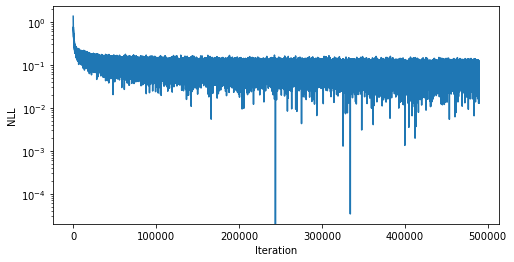

In [65]:
reporter.plot(log=True)

In [39]:
# load a model
# eq OT flow matching
# PATH = "models/alanine_eq_OT_flow_matching"
# checkpoint = torch.load(PATH)
# bg.load_state_dict(checkpoint['model_state_dict']), optim.load_state_dict(checkpoint['optimizer_state_dict'])
# OT flow matching
# PATH = "models/alanine_OT_flow_matching"
# bg.load_state_dict(torch.load(PATH))

<All keys matched successfully>

In [54]:
# use OTD in the evaluation process
bg.flow._integrator_atol = 1e-5
bg.flow._integrator_rtol = 1e-5
flow._use_checkpoints = False
flow._kwargs = {}

In [ ]:
import tqdm

n_samples = 2
n_sample_batches = 500
latent_np = np.empty(shape=(0))
samples_np = np.empty(shape=(0))
log_w_np = np.empty(shape=(0))
dlogp_np = np.empty(shape=(0))
energies_np = np.empty(shape=(0))
distances_x_np = np.empty(shape=(0))

for i in tqdm.tqdm(range(n_sample_batches)):
    with torch.no_grad():
        samples, latent, dlogp = bg.sample(n_samples, with_latent=True, with_dlogp=True)
        #latent = latent[0]
        #log_weights = bg.log_weights_given_latent(samples, latent, dlogp).detach().cpu().numpy()
        latent_np = np.append(latent_np, latent.detach().cpu().numpy())
        samples_np = np.append(samples_np, samples.detach().cpu().numpy())
        distances_x = distances_from_vectors(distance_vectors(samples.view(-1, n_particles, n_dimensions))).detach().cpu().numpy().reshape(-1)
        distances_x_np = np.append(distances_x_np, distances_x)

        #log_w_np = np.append(log_w_np, log_weights)
        dlogp_np = np.append(dlogp_np, as_numpy(dlogp))
        #energies = target.energy(samples/scaling).detach().cpu().numpy()
        #energies_np = np.append(energies_np, energies)
        

latent_np = latent_np.reshape(-1, dim)
samples_np = samples_np.reshape(-1, dim)

  3%|█▏                                    | 15/500 [45:04<24:00:56, 178.26s/it]

In [161]:
latent_np = latent_np.reshape(-1, dim)
samples_np = samples_np.reshape(-1, dim)

In [144]:
from bgflow import XTBEnergy, XTBBridge
import openmm as mm
atom_dict = {"H": 0, "C":1, "N":2, "O":3}
atom_types_xtb = []
for atom_name in ala_traj.topology.atoms:
    atom_types_xtb.append(atom_name.name[0])
atom_types_xtb = np.array([atom_dict[atom_type] for atom_type in atom_types_xtb])

temperature = 300
number_dict = {0: 1, 1:6, 2:7, 3:8}
numbers = np.array([number_dict[atom_type] for atom_type in atom_types_xtb])
target_xtb = XTBEnergy(
    XTBBridge(numbers=numbers, temperature=temperature, solvent="water"),
    two_event_dims=False
)

In [ ]:
energies_np = as_numpy(target_xtb.energy(torch.from_numpy(samples_np)/scaling))
latent_energies = prior.energy(torch.from_numpy(latent_np).cuda())

In [145]:
energy_offset = 34600
energies_np += energy_offset


In [146]:
data_holdout_xtb = torch.from_numpy(np.load("data/AD2_relaxed_holdout.npy")).reshape(-1, 66)
energies_data_holdout = target_xtb.energy(data_holdout_xtb[::9]/scaling)
energies_data_holdout += energy_offset

In [147]:
log_w_np = -as_numpy(energies_np) + as_numpy(latent_energies) + dlogp_np.reshape(-1,1)

In [148]:
energies_np = energies_np[np.isfinite(log_w_np)]
samples_np_plot = samples_np[np.isfinite(log_w_np).flatten()]
log_w_np = log_w_np[np.isfinite(log_w_np)]

In [149]:
sampling_efficiency(torch.from_numpy(log_w_np)).item()

0.015147062094627052

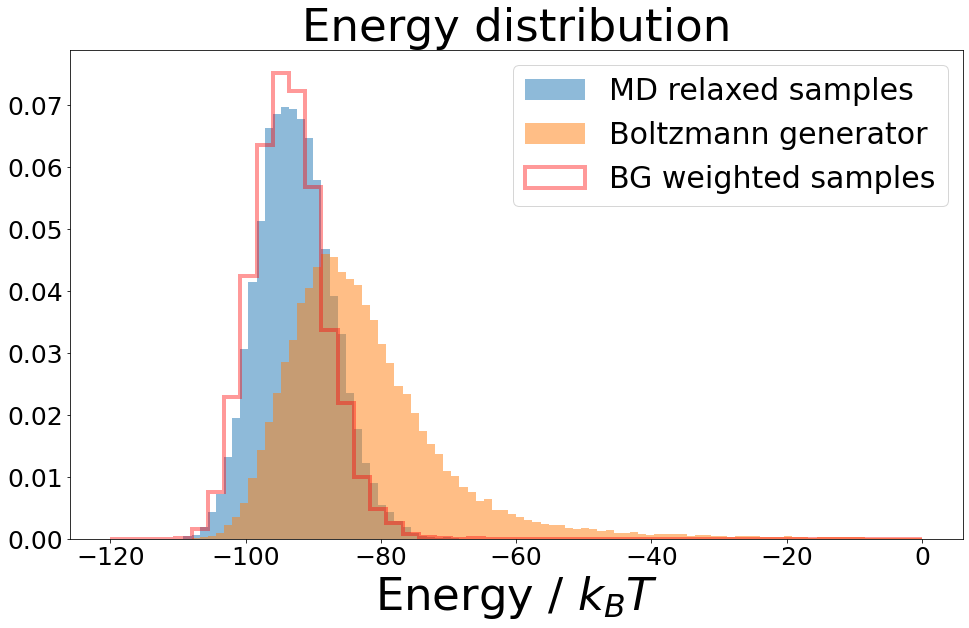

In [153]:
plt.figure(figsize=(16,9))

plt.hist(as_numpy(energies_data_holdout), bins=100, alpha=0.5, density=True, label="MD relaxed samples", range=(-120, 0));
plt.hist(energies_np, bins=100,range=(-120, 0) ,alpha=0.5, density=True, label="Boltzmann generator");
plt.hist(energies_np.reshape(-1), bins=50, density=True,  range=(-120, 0), alpha=0.4, histtype='step', linewidth=4,
         color="r", label="BG weighted samples", weights=np.exp(log_w_np));
plt.xticks(fontsize=25) 
plt.yticks(fontsize=25);
plt.legend(fontsize=30);
plt.xlabel(r"Energy / $k_B T$", fontsize=45)  
plt.title("Energy distribution", fontsize=45);


/storage/mi/leoma/libraries/en_flows_code/egnn/models2.py:195: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t).to(xs)


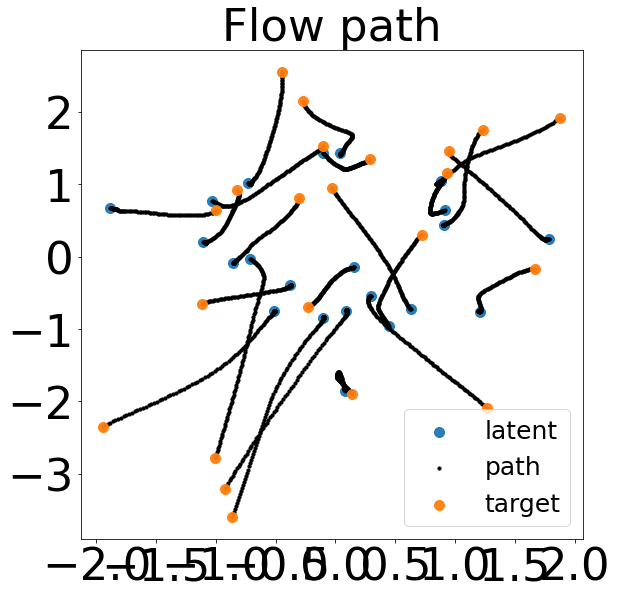

In [40]:
node = NeuralODE(
   net_dynamics, solver="dopri5", sensitivity="adjoint", atol=1e-4, rtol=1e-4
)
t_span = torch.linspace(0, 1, 100)

with torch.no_grad():
    traj = node.trajectory(
        prior.sample(1000),
        t_span=t_span,
    )
plot_flowpath_trajectory(traj[:, 1].reshape(-1, n_particles, n_dimensions)[:,:, :2])

In [ ]:
atom_dict = {"H": 0, "C":1, "N":2, "O":3}
atom_types2 = []
for atom_name in ala_traj.topology.atoms:
    atom_types2.append(atom_name.name[0])
atom_types2 = np.array([atom_dict[atom_type] for atom_type in atom_types2])
atom_colors = np.array(['grey','black',"b","r"])[np.array(atom_types2)]


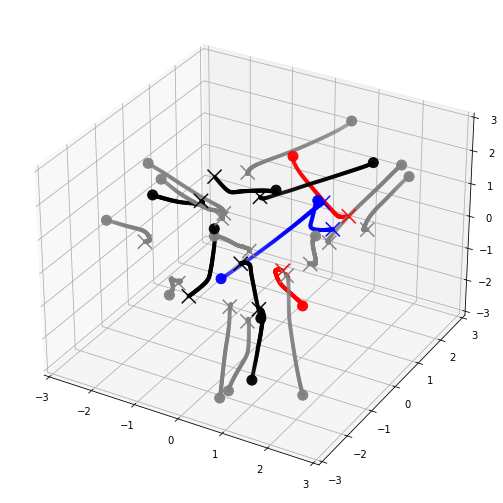

In [61]:
def plot_flowpath_trajectory_3d(traj, n_dimensions=3):
    fig = plt.figure(figsize=(9,9))
    ax = fig.add_subplot(projection='3d')
    latent_sample = as_numpy(traj[0].reshape(-1, n_dimensions))
    target_sample = as_numpy(traj[-1].reshape(-1, n_dimensions))
    
    ax.scatter(*latent_sample.T, alpha=0.95, label="latent",s=200,marker="x", color=atom_colors)

    traj = as_numpy(traj)
    #ax.scatter(traj[:, :,0].flatten(), traj[:, :,1].flatten(), traj[:, :,2].flatten(), color="black", s=10, label="path")
    for i in range(traj.shape[1]):
        ax.scatter(traj[:,i, 0], traj[:,i, 1], traj[:,i, 2], color=atom_colors[i],s=10, label="path")

    ax.scatter(*target_sample.T, alpha=0.95, label="target",s=100, color=atom_colors)
    ax.set_xlim((-3, 3))
    ax.set_ylim((-3, 3))
    ax.set_zlim((-3, 3))
    plt.savefig("figures/AD2-ot-flow-matching-sample.svg")
    #plt.title("Flow path", fontsize=45);
    #plt.xticks(fontsize=45) 
    #plt.yticks(fontsize=45);
    #plt.legend( fontsize=25);#67
plot_flowpath_trajectory_3d(traj[:,50].reshape(-1, n_particles, n_dimensions))

(10.105281, 9.265872)

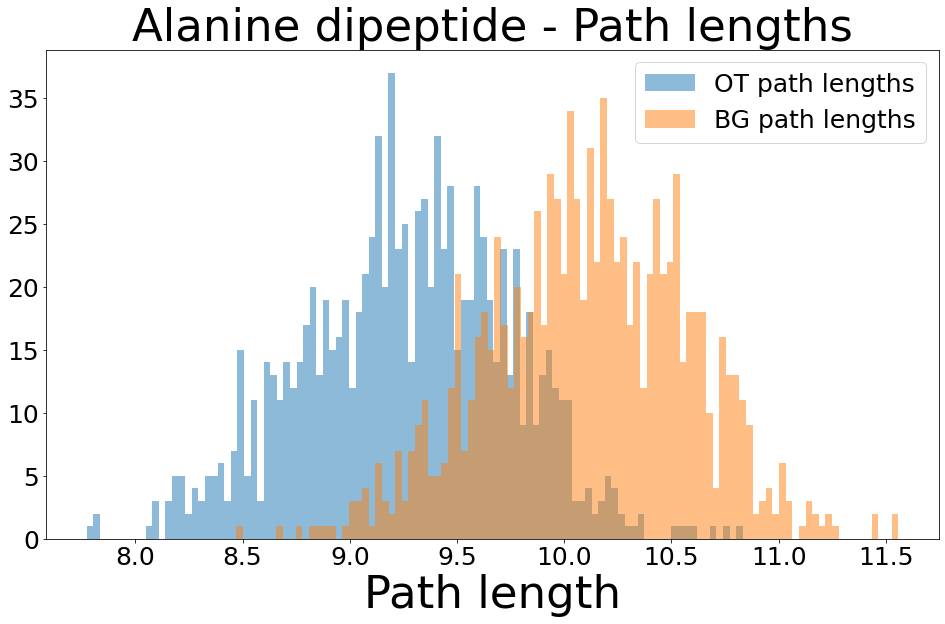

In [110]:
from scipy.optimize import linear_sum_assignment
perm_types = [0,1,3]

path_lengths = torch.linalg.norm(traj[1:]-traj[:-1], dim=-1).sum(0) #/ len(t_span)
ot_path_lengths = []
for i in range(len(traj[-1])):
    points1 = traj[0, i].reshape(n_particles, n_dimensions).cpu()
    points2 = traj[-1, i].reshape(n_particles, n_dimensions).cpu()
    
    for a in perm_types:
        atom_idxs = np.where(a == atom_types)[0]
        # compute pairwise distances between the two sets of points
        distances = torch.cdist(points1[atom_idxs], points2[atom_idxs])

        # use the Hungarian algorithm to solve the assignment problem
        row_idx, col_idx = linear_sum_assignment(distances**2)
        points2[atom_idxs] = points2[atom_idxs][col_idx]
    points2 = superpose_points(points2, points1).flatten()

    # reorder the second set of points according to the optimal assignment
    ot_path_lengths.append(np.linalg.norm(points2.flatten()-points1.flatten()))
ot_path_lengths = np.array(ot_path_lengths)



plt.figure(figsize=(16,9))
plt.hist(as_numpy(ot_path_lengths), bins=100, alpha=0.5, label="OT path lengths");
plt.hist(as_numpy(path_lengths), bins=100, alpha=0.5,label="BG path lengths");
plt.xlabel("Path length", fontsize=45)  
plt.title(f"Alanine dipeptide - Path lengths", fontsize=45)
plt.legend(fontsize=25)
plt.xticks(fontsize=25) 
plt.yticks(fontsize=25);
as_numpy(path_lengths).mean(), as_numpy(ot_path_lengths).mean()

In [ ]:
data_holdout_xtb = torch.from_numpy(np.load("data/AD2_relaxed_holdout.npy")).reshape(-1, 66).float()[::10]


In [ ]:
import tqdm
batch_size=200
n = len(data_holdout_xtb) // batch_size
nll = 0

for i in tqdm.tqdm(range(n)):
    batch = data_holdout_xtb[i*batch_size:i*batch_size+ batch_size].cuda()
    with torch.no_grad():
        nll += bg.energy(batch).mean() / n

nll

In [215]:
nll

(tensor(-107.5587, device='cuda:0'), 14)

In [ ]:
import tqdm
batch_size=200
n = len(data_smaller) // batch_size
nll_data_smaller = 0

for i in tqdm.tqdm(range(n)):
    batch = data_smaller[i*batch_size:i*batch_size+ batch_size].cuda()
    with torch.no_grad():
        nll_data_smaller += bg.energy(batch).mean() / n

nll_data_smaller

In [217]:
nll_data_smaller

(tensor(-107.7685, device='cuda:0'), 11)